# 速率预测特征表 / Rate-forecast feature tables

锁定设置：`/workspace/08_rate_forecast/split_2017_2025/` 已有的 2° × 30 天网格与 2017–2025 划分。本笔记本只构造特征表，**不训练模型**，也不改写上级目录 2017–2024 快照或源目录。

**泄漏硬规则：** 窗口 T 的一切事件派生特征，只能使用发震时刻严格早于 `T.start` 的地震。当前窗或之后的震级、深度、次数、位置一律不用。允许的时不变单元格属性：中心坐标、区域标志、训练集长期经验发生率、历史活动标志、到板块边界的距离。

核函数与基线 2 相同（τ=3×365.25 d，σ=200 km，截断 800 km，haversine，日期变更线感知），**不在 val/test 上搜索超参**。


In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from rate_forecast_lib import ROOT, KERNEL_TAU_DAYS, KERNEL_SIGMA_KM, KERNEL_CUTOFF_KM
from build_features import FEATURE_COLS, ID_COLS, main as build_main

sns.set_theme(style="whitegrid", font_scale=0.9)
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

windows = pd.read_csv(ROOT / "windows.csv", parse_dates=["window_start", "window_end"])
cells = pd.read_csv(ROOT / "cells_mask.csv")
ev = pd.read_csv(ROOT / "events_union_assigned.csv", parse_dates=["time_utc"])
locked = pd.read_csv(ROOT / "prevalence_by_split_region.csv")
complete = windows.loc[windows["entirely_in_split"]]
print("ROOT", ROOT)
print("complete windows", complete.groupby("split").size().to_dict(), "total", len(complete))
print("mask cells", len(cells), "hist-active union", int(cells.historically_active_union.sum()))
print("union events", len(ev), "M>=6", int((ev.mag >= 6).sum()))
print("excluded windows", windows.loc[windows.split.eq("none"), ["window_id", "exclude_reason"]].to_dict("records") if "exclude_reason" in windows.columns else windows.loc[windows.split.eq("none"), "window_id"].tolist())


ROOT /workspace/08_rate_forecast/split_2017_2025
complete windows {'holdout': 10, 'test': 108, 'train': 535, 'val': 97} total 750
mask cells 3594 hist-active union 538
union events 6524 M>=6 1959
excluded windows [535, 633, 742, 753]


## 特征列（锁定）

**建模特征（19）：** `lat_center`, `lon_sin`, `lon_cos`（经度球面编码；不要把原始 lon/lat 当欧氏坐标），区域标志与 `region_label`，训练集长期经验率 `p_empirical_train`（与基线 1 相同，仅完整训练窗），`historically_active`，`dist_to_plate_boundary_km`（PB2002_boundaries.shp，大圆距离），细胞过去 30/90/365 天 M≥5.5 次数，邻域核 `kernel_s` / `kernel_lambda=αs`（α 仅在训练集估计），`days_since_last_m55_cell` 与删失标志 `no_prior_m55_in_cell`（无历史时为缺失，不填 0），过去 365 天 800 km 内是否有 M≥6 及次数。

**标识 / 标签 / 诊断（不可作特征）：** `cell_id`, `window_id`, `window_start`, `window_end`, `split`, `y`, `diag_n_events_in_window`（使用窗内事件，仅诊断），`lon_center`（制图用，不作欧氏特征）。

完整定义见 `feature_dictionary.md`。


In [2]:
all_path = ROOT / "features_all_mask.parquet"
hist_path = ROOT / "features_hist_active.parquet"
if not (all_path.exists() and hist_path.exists()):
    print("parquet missing, building…")
    rc = build_main()
    print("build exit", rc)
else:
    print("using existing parquet")

df_all = pd.read_parquet(all_path)
df_hist = pd.read_parquet(hist_path)
print("all-mask", df_all.shape, "hist-active", df_hist.shape)
print("columns:", list(df_all.columns))
print("feature cols:", FEATURE_COLS)
print("id/label/diagnostic:", ID_COLS)
print(df_all.dtypes)


using existing parquet
all-mask (2695500, 27) hist-active (403500, 27)
columns: ['cell_id', 'window_id', 'window_start', 'window_end', 'split', 'y', 'diag_n_events_in_window', 'lon_center', 'lat_center', 'lon_sin', 'lon_cos', 'in_china_rectangle', 'in_pacific', 'in_overlap', 'region_label', 'p_empirical_train', 'historically_active', 'dist_to_plate_boundary_km', 'n_m55_cell_30d', 'n_m55_cell_90d', 'n_m55_cell_365d', 'kernel_s', 'kernel_lambda', 'days_since_last_m55_cell', 'no_prior_m55_in_cell', 'any_m6_800km_365d', 'n_m6_800km_365d']
feature cols: ['lat_center', 'lon_sin', 'lon_cos', 'in_china_rectangle', 'in_pacific', 'in_overlap', 'region_label', 'p_empirical_train', 'historically_active', 'dist_to_plate_boundary_km', 'n_m55_cell_30d', 'n_m55_cell_90d', 'n_m55_cell_365d', 'kernel_s', 'kernel_lambda', 'days_since_last_m55_cell', 'no_prior_m55_in_cell', 'any_m6_800km_365d', 'n_m6_800km_365d']
id/label/diagnostic: ['cell_id', 'window_id', 'window_start', 'window_end', 'split', 'y', 'di

## 行数、流行率与锁定基线对齐

`y` 是 **union** 区域在该细胞–窗口是否至少发生一次 M≥5.5。流行率只与锁定的 union 基线表对齐（不要与 rectangle/Pacific 单独计分混淆：那些标签只用对应区域事件）。


In [3]:
def counts_table(df, name):
    rows = []
    for split, sub in df.groupby("split", observed=True):
        rows.append({
            "table": name, "split": str(split),
            "n_rows": len(sub), "n_cells": sub.cell_id.nunique(),
            "n_windows": sub.window_id.nunique(),
            "n_positive": int(sub.y.sum()), "prevalence": float(sub.y.mean()),
        })
    rows.append({"table": name, "split": "total", "n_rows": len(df),
                 "n_cells": df.cell_id.nunique(), "n_windows": df.window_id.nunique(),
                 "n_positive": int(df.y.sum()), "prevalence": float(df.y.mean())})
    return pd.DataFrame(rows)

counts = pd.concat([counts_table(df_all, "all_mask"), counts_table(df_hist, "hist_active")], ignore_index=True)
display(counts)

cmp_rows = []
ok = True
for split in ["train", "val", "test", "holdout"]:
    lk = locked.loc[(locked.region == "union") & (locked.split == split)].iloc[0]
    for evset, d in [("all_mask_cells", df_all), ("historically_active", df_hist)]:
        sub = d.loc[d.split == split]
        if evset == "all_mask_cells":
            exp_n, exp_pos, exp_p = int(lk.n_cell_windows_all), int(lk.n_positive_cell_windows_all), float(lk.prevalence_all)
        else:
            exp_n, exp_pos, exp_p = int(lk.n_cell_windows_hist_active), int(lk.n_positive_cell_windows_hist_active), float(lk.prevalence_hist_active)
        match = (len(sub) == exp_n) and (int(sub.y.sum()) == exp_pos) and np.isclose(sub.y.mean(), exp_p)
        ok = ok and match
        cmp_rows.append({"split": split, "eval_set": evset, "n_rows": len(sub),
                         "n_positive": int(sub.y.sum()), "prevalence": float(sub.y.mean()),
                         "locked_n": exp_n, "locked_pos": exp_pos, "locked_p": exp_p, "match": match})
cmp = pd.DataFrame(cmp_rows)
display(cmp)
print("prevalence matches locked union baseline:", ok)
assert ok

cells_u = df_all.drop_duplicates("cell_id")
print("region cells:",
      "rectangle", int(cells_u.in_china_rectangle.sum()),
      "pacific", int(cells_u.in_pacific.sum()),
      "overlap", int(cells_u.in_overlap.sum()),
      "hist-active", int(cells_u.historically_active.sum()))
# geometry flags only (y remains union occurrence)
geo = (df_all.groupby("split", observed=True)
       .agg(n_rect=("in_china_rectangle", "sum"),
            n_pac=("in_pacific", "sum"),
            n_overlap=("in_overlap", "sum"))
       .reset_index())
display(geo)


,table,split,n_rows,n_cells,n_windows,n_positive,prevalence
0,all_mask,holdout,35940,3594,10,67,0.001864
1,all_mask,test,388152,3594,108,620,0.001597
2,all_mask,train,1922790,3594,535,3509,0.001825
3,all_mask,val,348618,3594,97,683,0.001959
4,all_mask,total,2695500,3594,750,4879,0.001810
5,hist_active,holdout,5380,538,10,62,0.011524
6,hist_active,test,58104,538,108,577,0.009930
7,hist_active,train,287830,538,535,3509,0.012191
8,hist_active,val,52186,538,97,651,0.012475
9,hist_active,total,403500,538,750,4799,0.011893


,split,eval_set,n_rows,n_positive,prevalence,locked_n,locked_pos,locked_p,match
0,train,all_mask_cells,1922790,3509,0.001825,1922790,3509,0.001825,True
1,train,historically_active,287830,3509,0.012191,287830,3509,0.012191,True
2,val,all_mask_cells,348618,683,0.001959,348618,683,0.001959,True
3,val,historically_active,52186,651,0.012475,52186,651,0.012475,True
4,test,all_mask_cells,388152,620,0.001597,388152,620,0.001597,True
5,test,historically_active,58104,577,0.009930,58104,577,0.009930,True
6,holdout,all_mask_cells,35940,67,0.001864,35940,67,0.001864,True
7,holdout,historically_active,5380,62,0.011524,5380,62,0.011524,True


prevalence matches locked union baseline: True
region cells: rectangle 988 pacific 2632 overlap 26 hist-active 538


,split,n_rect,n_pac,n_overlap
0,holdout,9880,26320,260
1,test,106704,284256,2808
2,train,528580,1408120,13910
3,val,95836,255304,2522


## 缺失与删失：细胞内距上次 M≥5.5 的时间

无此前事件时，`days_since_last_m55_cell` 为缺失，`no_prior_m55_in_cell=True`，不填 0。第一个训练窗（1965-01-01 起）应全部删失。历史上活动细胞在 val/test/holdout 上不应再删失（定义要求训练期内已有活动）。


,table,split,n_rows,n_no_prior,frac_no_prior,flag_matches_na,min_days_if_observed
0,all_mask,holdout,35940,30028,0.835504,True,0.251403
1,all_mask,test,388152,325764,0.839269,True,0.031955
2,all_mask,train,1922790,1721775,0.895457,True,0.002700
3,all_mask,val,348618,295256,0.846933,True,0.012298
4,hist_active,holdout,5380,0,0.000000,True,0.251403
5,hist_active,test,58104,0,0.000000,True,0.031955
6,hist_active,train,287830,86815,0.301619,True,0.002700
7,hist_active,val,52186,0,0.000000,True,0.012298


first train window frac no prior: all-mask 1.0 hist-active 1.0
other feature nulls: {}


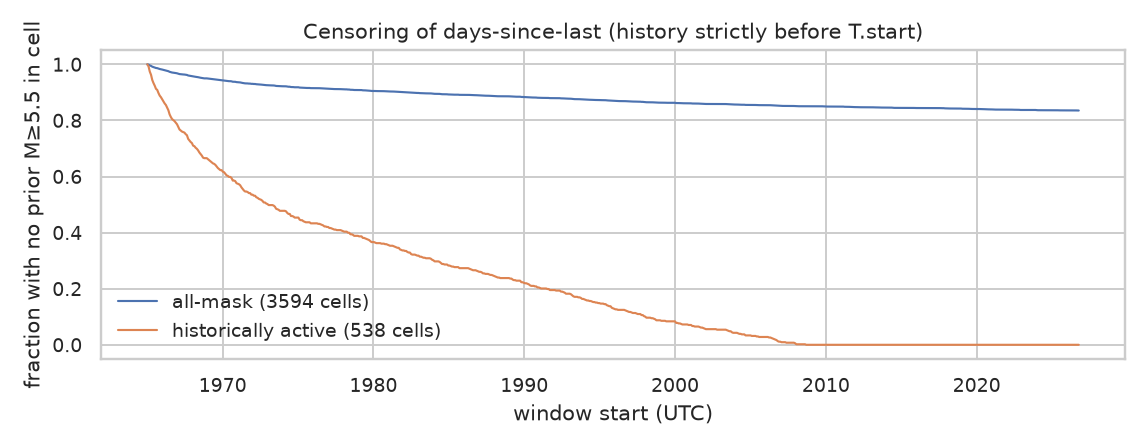

In [4]:
miss_rows = []
for name, d in [("all_mask", df_all), ("hist_active", df_hist)]:
    for split, sub in d.groupby("split", observed=True):
        consistent = bool((sub.no_prior_m55_in_cell == sub.days_since_last_m55_cell.isna()).all())
        miss_rows.append({
            "table": name, "split": str(split), "n_rows": len(sub),
            "n_no_prior": int(sub.no_prior_m55_in_cell.sum()),
            "frac_no_prior": float(sub.no_prior_m55_in_cell.mean()),
            "flag_matches_na": consistent,
            "min_days_if_observed": float(sub.loc[~sub.no_prior_m55_in_cell, "days_since_last_m55_cell"].min()) if (~sub.no_prior_m55_in_cell).any() else np.nan,
        })
miss = pd.DataFrame(miss_rows)
display(miss)
assert miss.flag_matches_na.all()

first_all = float(df_all.loc[df_all.window_id == 0, "no_prior_m55_in_cell"].mean())
first_hist = float(df_hist.loc[df_hist.window_id == 0, "no_prior_m55_in_cell"].mean())
print("first train window frac no prior: all-mask", first_all, "hist-active", first_hist)
assert first_all == 1.0 and first_hist == 1.0
print("other feature nulls:",
      {c: int(df_all[c].isna().sum()) for c in FEATURE_COLS if c != "days_since_last_m55_cell" and df_all[c].isna().any()})

# time series of censoring
series = (df_all.groupby(["window_start", "split"], observed=True)
          .agg(all_mask=("no_prior_m55_in_cell", "mean"))
          .reset_index())
series_h = (df_hist.groupby("window_start", observed=True)["no_prior_m55_in_cell"].mean()
            .rename("hist_active").reset_index())
series = series.merge(series_h, on="window_start")
fig, ax = plt.subplots(figsize=(8.2, 3.2))
ax.plot(series.window_start, series.all_mask, lw=1.1, label="all-mask (3594 cells)")
ax.plot(series.window_start, series.hist_active, lw=1.1, label="historically active (538 cells)")
ax.set_ylabel("fraction with no prior M≥5.5 in cell")
ax.set_xlabel("window start (UTC)")
ax.set_title("Censoring of days-since-last (history strictly before T.start)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "features_censoring_days_since.png", dpi=140)
plt.close(fig)
display(Image(filename=str(FIG / "features_censoring_days_since.png")))


## 泄漏抽查

对若干训练 / 验证 / 测试 / 预留窗口，用 `t_e < T.start` 手工重算细胞次数、距上次事件、800 km 内 M≥6，以及与基线相同的核 `s`。窗内事件不得进入历史特征。


In [5]:
from build_features import leakage_checks, load_inputs

qa_path = ROOT / "qa_features.json"
qa = json.loads(qa_path.read_text())
leak = qa["leakage_check"]
print("windows checked:", leak["windows_spot_checked"])
print("value checks:", leak["n_feature_value_checks"], "mismatches:", leak["n_mismatches"])
print("kernel recomputes:", leak["kernel_recomputed"], "kernel mismatches:", leak["kernel_mismatches"])
print("events in scored windows with time < window_start:", leak["events_in_scored_windows_with_time_before_window_start"])
print("passed:", leak["passed"])
assert leak["passed"]

# one transparent example: first test window, a historically active cell with a prior event
w_test = df_hist.loc[df_hist.split == "test"].window_id.min()
t0 = df_hist.loc[df_hist.window_id == w_test, "window_start"].iloc[0]
ex = df_hist.loc[(df_hist.window_id == w_test) & (~df_hist.no_prior_m55_in_cell)].iloc[0]
ev_t = ev.copy()
ev_t["time_utc"] = pd.to_datetime(ev_t["time_utc"], utc=True)
t0 = pd.Timestamp(t0)
cid = str(ex.cell_id)
hist = ev_t.loc[(ev_t.cell_id.astype(str) == cid) & (ev_t.time_utc < t0)]
in_win = ev_t.loc[(ev_t.cell_id.astype(str) == cid) & (ev_t.time_utc >= t0) & (ev_t.time_utc < pd.Timestamp(ex.window_end))]
print(f"example cell {cid}  window {int(w_test)}  T.start={t0}")
print("table n365", int(ex.n_m55_cell_365d), "manual", int((hist.time_utc >= t0 - pd.Timedelta(days=365)).sum()))
print("table days_since", float(ex.days_since_last_m55_cell), "manual", (t0 - hist.time_utc.max()) / pd.Timedelta(days=1))
print("events inside current window (must not be in history):", len(in_win))
if len(in_win):
    print(in_win.time_utc.tolist())


windows checked: [0, 267, 534, 223, 515, 447, 536, 584, 632, 576, 565, 596, 634, 688, 741, 693, 711, 700, 743, 748, 752, 748, 743, 749]
value checks: 720 mismatches: 0
kernel recomputes: 30 kernel mismatches: 0
events in scored windows with time < window_start: 0
passed: True
example cell C-180_-66  window 634  T.start=2017-01-28 00:00:00+00:00
table n365 0 manual 0
table days_since 716.1045532226562 manual 716.1045766203704
events inside current window (must not be in history): 0


## 板块边界距离与特征分布

`dist_to_plate_boundary_km` 由细胞中心到 `PB2002_boundaries.shp` 的最近点大圆距离（沿线约 2 km 加密）。已包含，未编造。


count    3594.000000
mean     1111.916626
std       974.285034
min         0.595042
25%       294.239830
50%       821.604645
75%      1731.465454
max      3946.314697
Name: dist_to_plate_boundary_km, dtype: float64
min/max km 0.5950424671173096 3946.314697265625


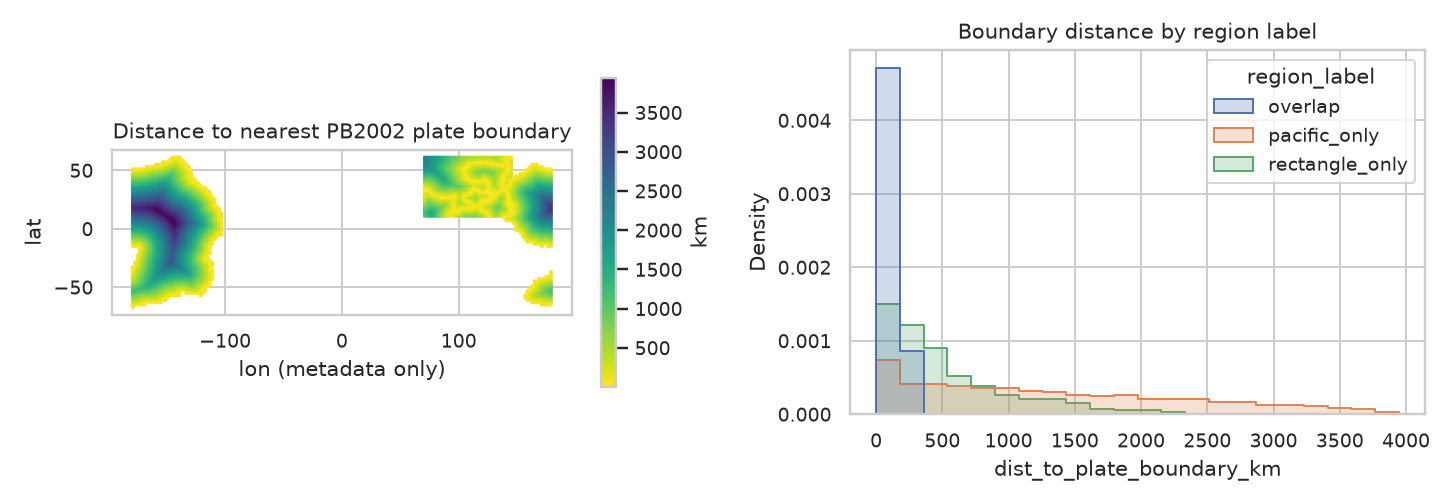

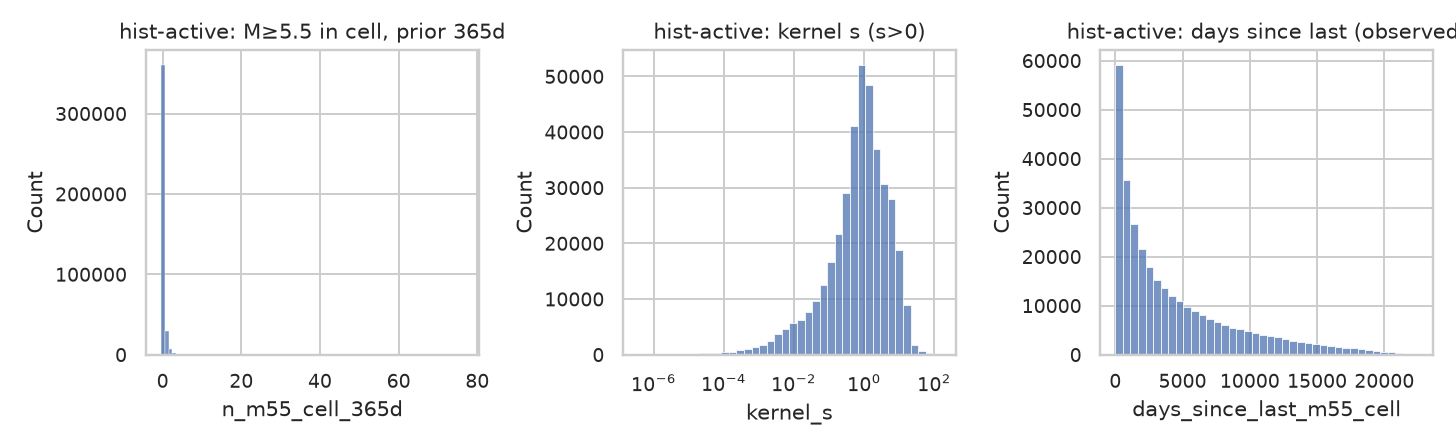

kernel τ, σ, cutoff, α: 1095.75 200.0 800.0 0.005506486521694776
plate-boundary distance included: True


In [6]:
cell_feat = df_all.drop_duplicates("cell_id")
print(cell_feat.dist_to_plate_boundary_km.describe())
print("min/max km", float(cell_feat.dist_to_plate_boundary_km.min()), float(cell_feat.dist_to_plate_boundary_km.max()))

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.6))
sc = axes[0].scatter(
    cell_feat.lon_center, cell_feat.lat_center,
    c=cell_feat.dist_to_plate_boundary_km, s=4, cmap="viridis_r", linewidths=0,
)
cb = fig.colorbar(sc, ax=axes[0], shrink=0.85)
cb.set_label("km")
axes[0].set_xlabel("lon (metadata only)")
axes[0].set_ylabel("lat")
axes[0].set_title("Distance to nearest PB2002 plate boundary")
axes[0].set_aspect("equal", adjustable="box")
sns.histplot(cell_feat, x="dist_to_plate_boundary_km", hue="region_label",
             element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Boundary distance by region label")
fig.tight_layout()
fig.savefig(FIG / "features_dist_to_plate_boundary.png", dpi=140)
plt.close(fig)
display(Image(filename=str(FIG / "features_dist_to_plate_boundary.png")))

fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.2))
sns.histplot(df_hist, x="n_m55_cell_365d", discrete=True, ax=axes[0])
axes[0].set_title("hist-active: M≥5.5 in cell, prior 365d")
sns.histplot(df_hist.loc[df_hist.kernel_s > 0], x="kernel_s", bins=40, log_scale=(True, False), ax=axes[1])
axes[1].set_title("hist-active: kernel s (s>0)")
obs = df_hist.loc[~df_hist.no_prior_m55_in_cell, "days_since_last_m55_cell"]
sns.histplot(obs, bins=40, ax=axes[2])
axes[2].set_title("hist-active: days since last (observed)")
fig.tight_layout()
fig.savefig(FIG / "features_history_distributions.png", dpi=140)
plt.close(fig)
display(Image(filename=str(FIG / "features_history_distributions.png")))
print("kernel τ, σ, cutoff, α:", KERNEL_TAU_DAYS, KERNEL_SIGMA_KM, KERNEL_CUTOFF_KM, qa["kernel"]["alpha_train_only"])
print("plate-boundary distance included:", qa["plate_boundary_distance_included"])


## 输出文件与哈希

本步不训练、不改写源目录与上级 2017–2024 快照。


In [7]:
def sha256(p: Path) -> str:
    h = hashlib.sha256()
    with p.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

files = [
    ROOT / "features_all_mask.parquet",
    ROOT / "features_hist_active.parquet",
    ROOT / "feature_dictionary.md",
    ROOT / "feature_dictionary.json",
    ROOT / "qa_features.json",
    ROOT / "qa_features.md",
    ROOT / "build_features.py",
]
out = pd.DataFrame([{"file": p.name, "bytes": p.stat().st_size, "sha256": sha256(p), "path": str(p)} for p in files])
display(out)
print("no training performed")


,file,bytes,sha256,path
0,features_all_mask.parquet,23777131,1c5ee7666711cae4c191029eb2a1a4fde5715efcb7439c...,/workspace/08_rate_forecast/split_2017_2025/fe...
1,features_hist_active.parquet,6793001,81d8b9aece08a8f897d81d6128a2458d5c8e40127a4c1b...,/workspace/08_rate_forecast/split_2017_2025/fe...
2,feature_dictionary.md,4483,e24cd81e8d7abaae2b2096914f84c61f3c5f5252e96367...,/workspace/08_rate_forecast/split_2017_2025/fe...
3,feature_dictionary.json,5803,421bb7a2ecdbf3ee68175c67bfe864f34451146ddf7d34...,/workspace/08_rate_forecast/split_2017_2025/fe...
4,qa_features.json,8150,6a7a046e3108bd15548caf645d5d2973dadfcef5e5e450...,/workspace/08_rate_forecast/split_2017_2025/qa...
5,qa_features.md,1030,fc34c5b74cdc699b3a9fa8b0c35205d9abf2fd1298e4fd...,/workspace/08_rate_forecast/split_2017_2025/qa...
6,build_features.py,35871,a459bd74018595bd7ae36f63dbac3f418df6c88d077787...,/workspace/08_rate_forecast/split_2017_2025/bu...


no training performed
